# [Lab Session 4](deconvolution.ipynb)

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from skimage.restoration import wiener
from scipy.signal import convolve2d as conv
from scipy.stats import multivariate_normal as multi_normal

np.random.seed(0)

Load the image.

In [3]:
img = plt.imread('data/cells.png')[128:384, 128:384]
plt.imshow(img, 'Blues')
plt.colorbar()

**[Task 1.]()** Apply the following PSF to the image and then display it.

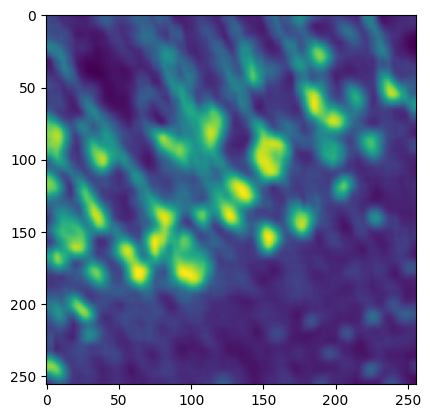

In [5]:
psf_size = 10
psf = np.ones((psf_size, psf_size)) / psf_size ** 2
g= conv(img,psf,mode='same',boundary='symm')
plt.imshow(g)

**[Task 2.]()** Have a look at the Gaussian PSF which is not uniformly distributed. Apply it to the image.

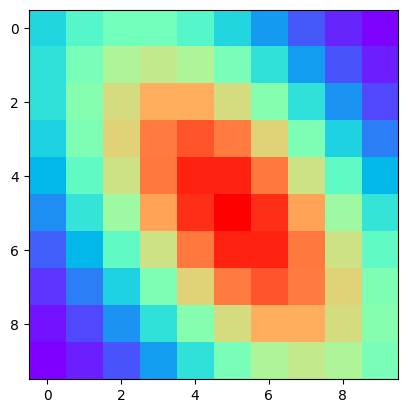

In [6]:
def create_psf(size):
    factor = size * 1.8
    x, y = np.mgrid[0:size:1, 0:size:1]
    pos = np.empty(x.shape + (2,))
    pos[:, :, 0] = x
    pos[:, :, 1] = y
    rv = multi_normal([int(size / 2), (int(size / 2))], [[factor * 1., factor * 1.2], [factor * .5, factor * .7]])
    return rv.pdf(pos)

plt.imshow(create_psf(psf_size), 'rainbow')

Apply the second psf to the image:

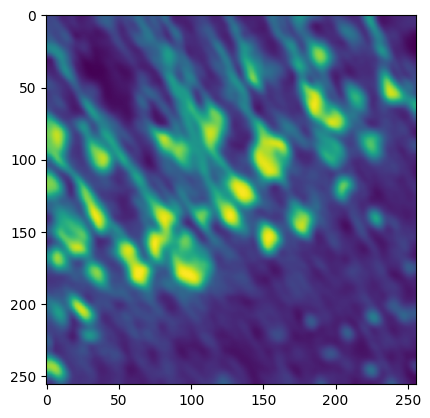

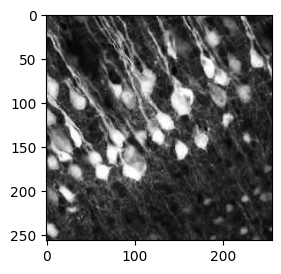

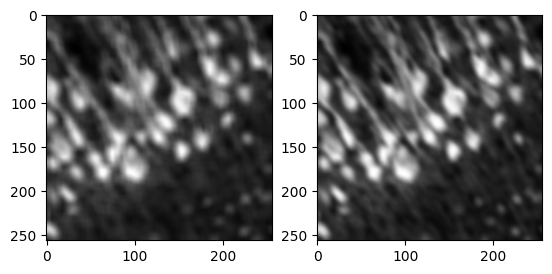

In [7]:

gpsf=create_psf(10)

g1= conv(img,gpsf,mode='same',boundary='symm')
plt.imshow(g1)

plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(img, 'gray')
plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(g, 'gray')
plt.subplot(1, 2, 2)
plt.imshow(g1, 'gray')


**[Task 3.]()** Implement a reusable function that performs the Richardson-Lucy deconvolution.

In [8]:
def richardson_lucy_deconvolution(image, psf, n_iterations):
    img_deconv = np.full(image.shape, 0.5)
    
    
    for i in range (n_iterations):
       convolved_term1= image/(conv(img_deconv,psf,mode='same',boundary='symm')+1e-10)
       convolved_term= conv(convolved_term1,(np.flip(psf)), mode='same',boundary='symm')
       
       img_deconv= img_deconv* convolved_term
       


   
    
    img_deconv = img_deconv.clip(0,1)
    return img_deconv

**[Task 4.]()** Apply the Richardson-Lucy deconvolution to the blurred image.

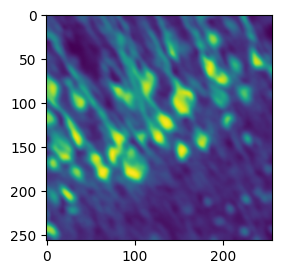

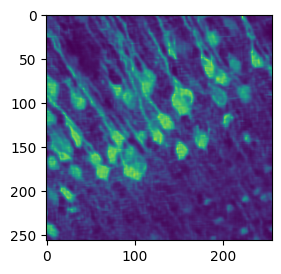

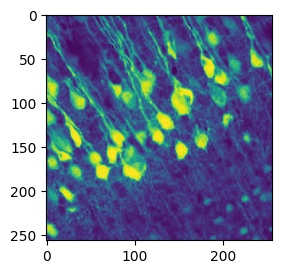

In [9]:
 img_restored=richardson_lucy_deconvolution(g1, gpsf, 450)
 plt.figure()
 plt.subplot(1, 2, 2)
 plt.imshow(g1)
 plt.figure()
 plt.subplot(1, 2, 1)
 plt.imshow(img_restored)
 plt.figure()
 plt.subplot(1, 2, 1)
 plt.imshow(img)

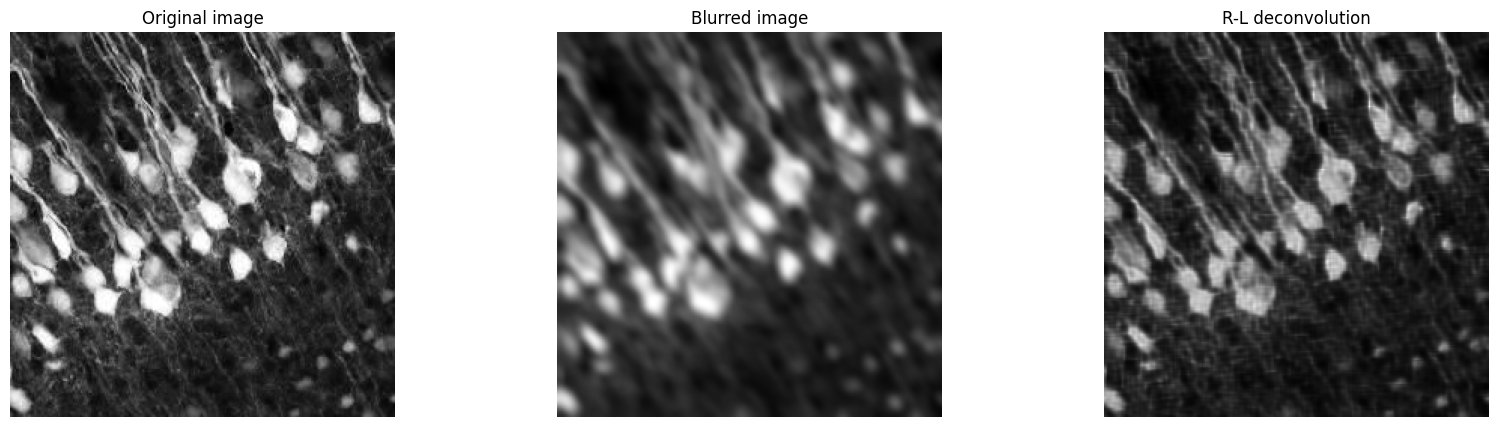

In [10]:
plt.figure(figsize=(20,5))
plt.subplot(1, 3, 1)
plt.axis('off')
plt.imshow(img, 'gray')
plt.title('Original image')
plt.subplot(1, 3, 2)
plt.axis('off')
plt.imshow(g1, 'gray')
plt.title('Blurred image')
plt.subplot(1, 3, 3)
plt.axis('off')
plt.imshow(img_restored, 'gray')
plt.title('R-L deconvolution')
plt.show()

**[Task 5.]()** Add noise to the image, use the R-L deconvolution again.

In [11]:
noise = (np.random.normal(loc=0,size=img.shape))
reduce_factor = 5
noise = noise / reduce_factor

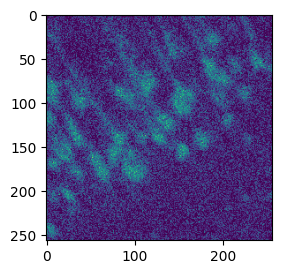

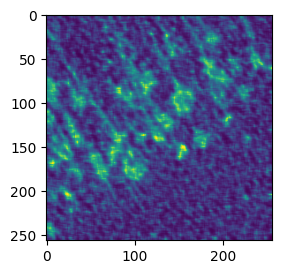

In [12]:
img_whitenoise= g1 + noise

arr = np.array(img_whitenoise, dtype=np.float32)
img_whitenoiseclipped = np.clip(arr, 0, 255)

plt.figure()
plt.subplot(1, 2, 2)
plt.imshow(img_whitenoiseclipped)
img_whitenoise_restored = richardson_lucy_deconvolution(img_whitenoiseclipped, gpsf, 10)
plt.figure()
plt.subplot(1, 2, 2)
plt.imshow(img_whitenoise_restored)

**[Task 6.]()** Compare your R-L implementation to a wiener deconvolution.

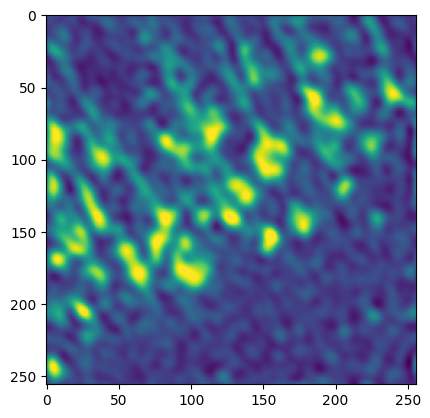

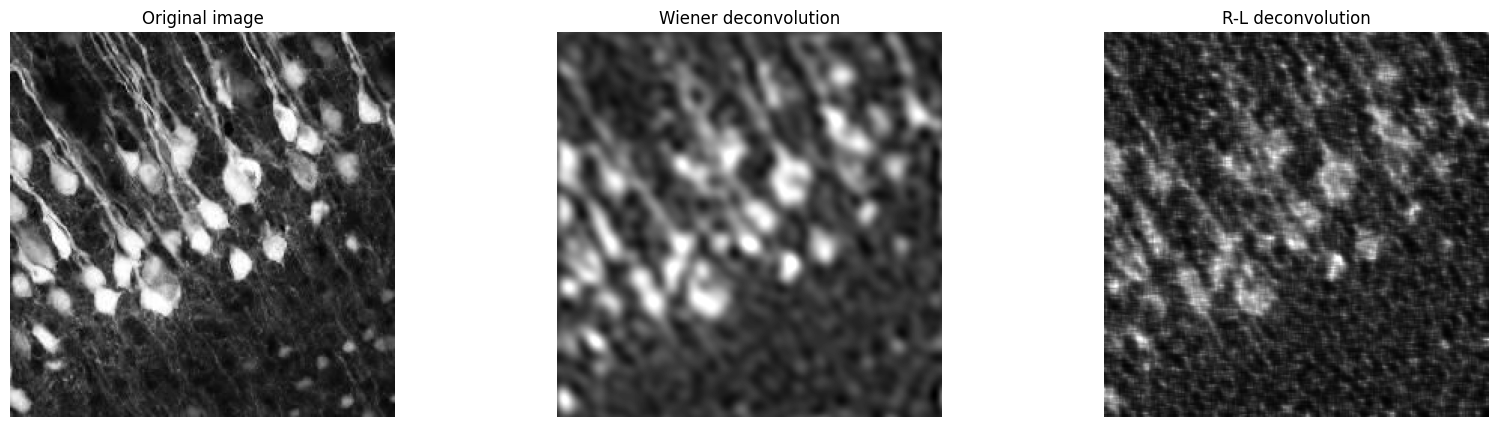

In [13]:
img_wiener=wiener(img_whitenoiseclipped,gpsf,balance=2,clip=True)
plt.imshow(img_wiener)

plt.figure(figsize=(20,5))
plt.subplot(1, 3, 1)
plt.axis('off')
plt.imshow(img, 'gray')
plt.title('Original image')
plt.subplot(1, 3, 2)
plt.axis('off')
plt.imshow(img_wiener, 'gray')
plt.title('Wiener deconvolution')
plt.subplot(1, 3, 3)
plt.axis('off')
plt.imshow(img_whitenoise_restored, 'gray')
plt.title('R-L deconvolution')
plt.show()

**[Task 7.]()** Repeat Tasks 4–6 using a smaller value for the size of the PSF.

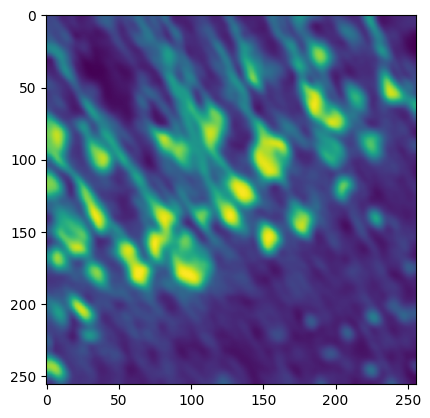

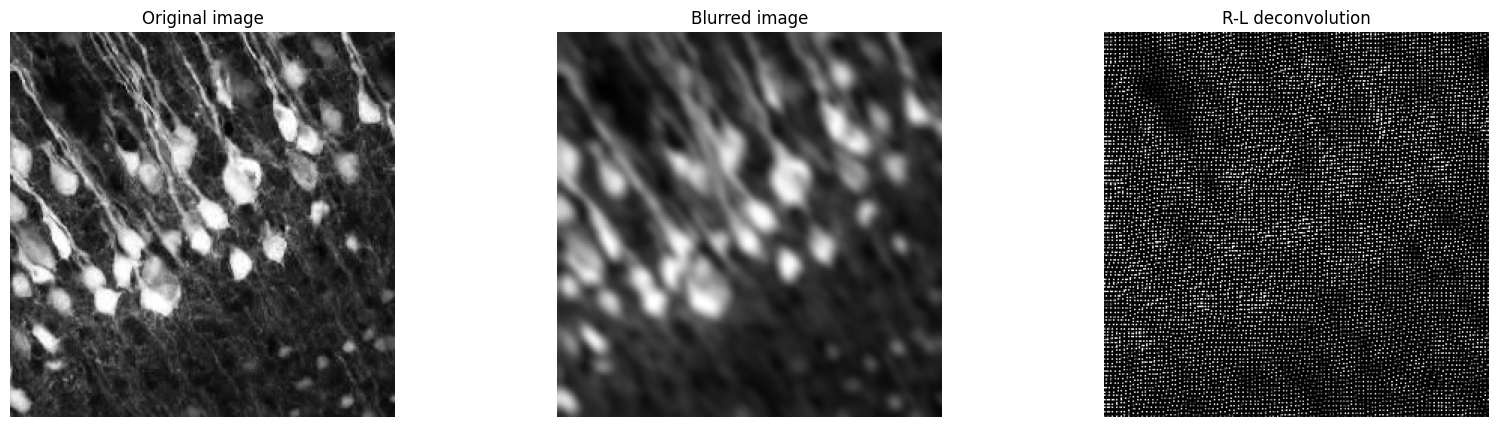

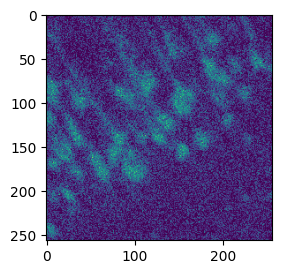

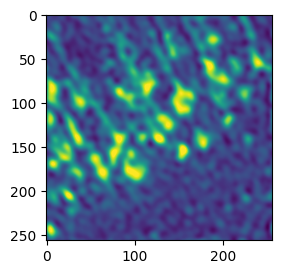

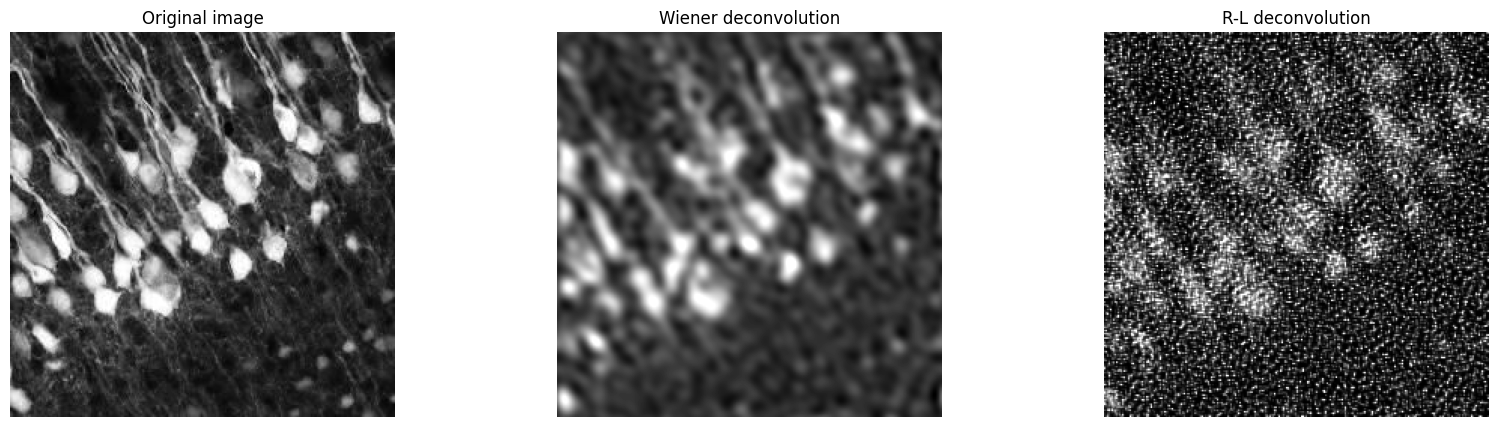

In [14]:
gpsf1=create_psf(4)

g2= conv(img,gpsf,mode='same',boundary='symm')
plt.imshow(g2)

img_restored1=richardson_lucy_deconvolution(g2, gpsf1, 450)
plt.figure(figsize=(20,5))
plt.subplot(1, 3, 1)
plt.axis('off')
plt.imshow(img, 'gray')
plt.title('Original image')
plt.subplot(1, 3, 2)
plt.axis('off')
plt.imshow(g2, 'gray')
plt.title('Blurred image')
plt.subplot(1, 3, 3)
plt.axis('off')
plt.imshow(img_restored1, 'gray')
plt.title('R-L deconvolution')
plt.show()

img_whitenoise1= g2 + noise

arr = np.array(img_whitenoise1, dtype=np.float32)
img_whitenoiseclipped1 = np.clip(arr, 0, 255)

plt.figure()
plt.subplot(1, 2, 2)
plt.imshow(img_whitenoiseclipped1)
img_whitenoise_restored1 = richardson_lucy_deconvolution(img_whitenoiseclipped1, gpsf1, 10)
plt.figure()
plt.subplot(1, 2, 2)
plt.imshow(img_whitenoise_restored1)

img_wiener1=wiener(img_whitenoiseclipped,gpsf,balance=2,clip=True)
plt.imshow(img_wiener1)

plt.figure(figsize=(20,5))
plt.subplot(1, 3, 1)
plt.axis('off')
plt.imshow(img, 'gray')
plt.title('Original image')
plt.subplot(1, 3, 2)
plt.axis('off')
plt.imshow(img_wiener1, 'gray')
plt.title('Wiener deconvolution')
plt.subplot(1, 3, 3)
plt.axis('off')
plt.imshow(img_whitenoise_restored1, 'gray')
plt.title('R-L deconvolution')
plt.show()
 



**[Task 8.]()** Use a wrong PSF to restore the image

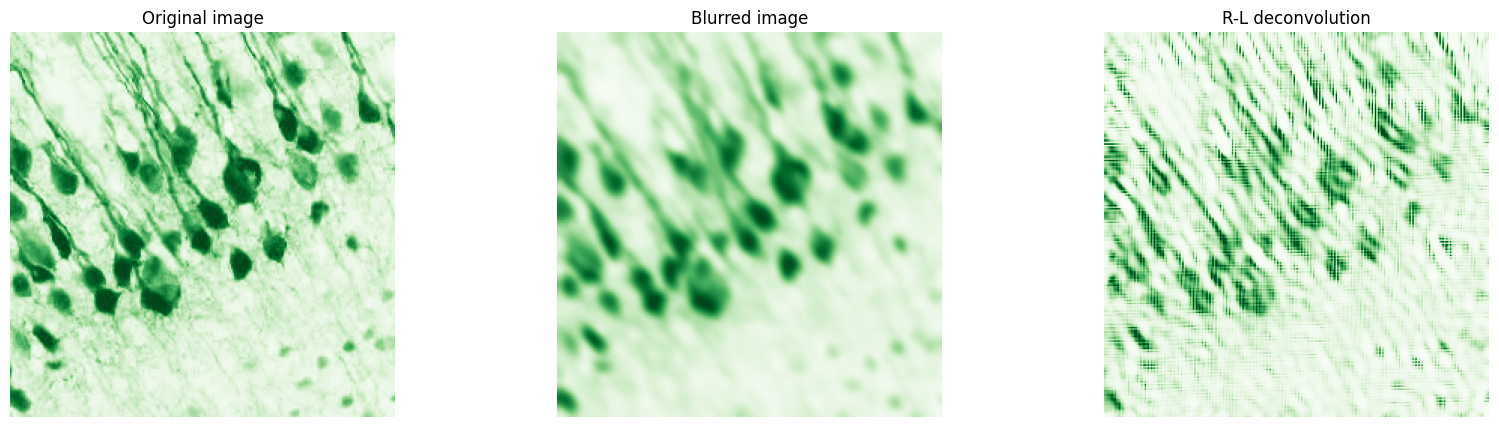

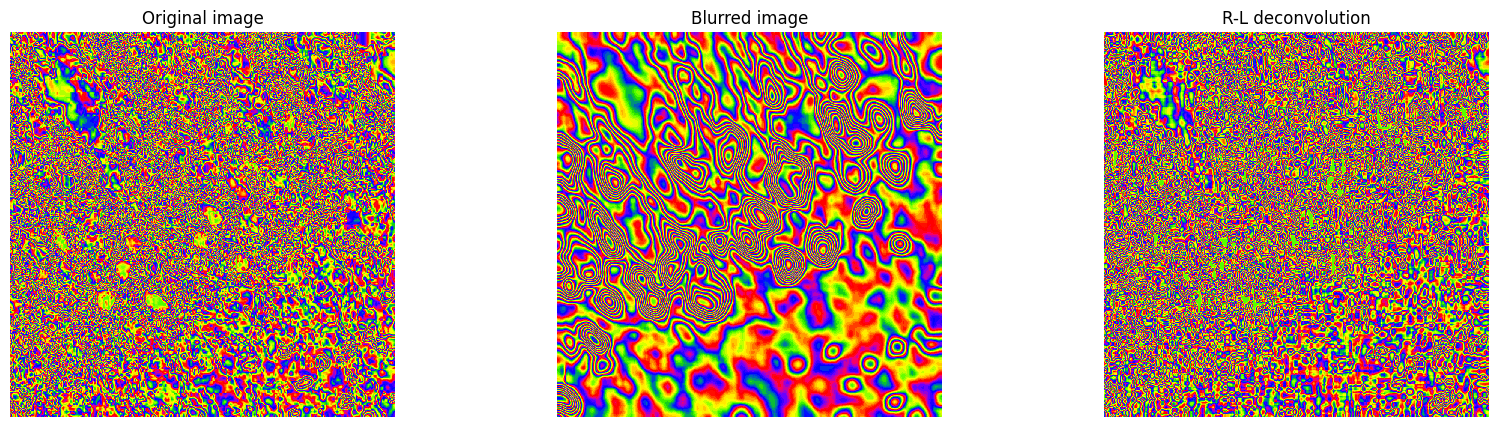

In [25]:
img_restored_3=richardson_lucy_deconvolution(g1, psf, 450)
plt.figure(figsize=(20,5))
plt.subplot(1, 3, 1)
plt.axis('off')
plt.imshow(img, 'Greens')
plt.title('Original image')
plt.subplot(1, 3, 2)
plt.axis('off')
plt.imshow(g1, 'Greens')
plt.title('Blurred image')
plt.subplot(1, 3, 3)
plt.axis('off')
plt.imshow(img_restored_3, 'Greens')
plt.title('R-L deconvolution')
plt.show()

img_restored_4=richardson_lucy_deconvolution(g, gpsf, 450)
plt.figure(figsize=(20,5))
plt.subplot(1, 3, 1)
plt.axis('off')
plt.imshow(img, 'prism')
plt.title('Original image')
plt.subplot(1, 3, 2)
plt.axis('off')
plt.imshow(g, 'prism')
plt.title('Blurred image')
plt.subplot(1, 3, 3)
plt.axis('off')
plt.imshow(img_restored_4, 'prism')
plt.title('R-L deconvolution')
plt.show()